In [1]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import numpy.random as nr
import jax
import scipy
from gestimators import BF
from IMH2 import IndMH
import matplotlib.pyplot as plt
from gdistribution import gprior, mix_normal
import math

In [2]:
# def load_data():
#         file = '/home/ranbot/optionpricing/data/ripley.mat'
#         mat = scipy.io.loadmat(file)
#         data = mat['X']
#         inputs = data[:, 0:-1]
#         print(inputs.shape)
#         outputs = data[:, -1]
#         return inputs, outputs

# input, output = load_data()

# n_predata = 50
# def gen_data():
#     X = nr.multivariate_normal(np.zeros(5), np.eye(5), n_predata)
#     y = np.zeros(n_predata)
#     for i in range(n_predata):
#         y[i] = nr.normal(2*X[i,3] + 5*X[i,4], 2.5)
#     #write to file
#     df = pd.DataFrame(X)
#     df['y'] = y
#     df.to_csv('data.csv', index=False)
#     return X, y

# gen_data()

In [3]:
#read from file
def read_data():
    df = pd.read_csv('data.csv')
    X = df.values[:, 0:-1]
    y = df.values[:, -1]
    return X, y

input, output = read_data()
input = input[:,3:]
dim = input.shape[1]
N = input.shape[0]
s = 2.5
cov0 = np.linalg.inv(input.T @ input)
print(cov0)
print(dim)
print(N)

[[ 0.01702346 -0.00231604]
 [-0.00231604  0.01804721]]
2
50


In [4]:
def true_mean():
    const = (2*np.pi)**(-N/2)*s**(-N)*np.exp(-0.5*s**(-2)*np.sum(output**2))
    t = np.sum(output[:, np.newaxis]*input, axis=0)
    expcoef = 0.5*s**(-2)*(t.T @ cov0 @ t)
    def integrant(x):
        return const*np.exp(expcoef * x / (x+s**2)) *(1+x/s**2)**(-dim/2) * (1+x)**(-2)
    
    return scipy.integrate.quad(integrant, 0, np.inf)[0]

print(true_mean())
    

6.749795393026463e-54


10 [0.13369393 0.84372211 0.02258395] [ 15.61514701   1.53189364 175.10664281] 0.9999999999999939
20 [0.15824448 0.82831578 0.01343975] [ 15.57708348   1.19132467 289.48170872] 0.9999999999999996
30 [0.16283213 0.82305963 0.01410824] [ 14.97615492   1.17501149 278.98520379] 0.999999999999998
40 [0.16326439 0.82254184 0.01419377] [ 14.91421655   1.17355886 277.68150732] 1.0000000000000002
50 [0.1633055  0.82249229 0.01420221] [ 14.90824813   1.17342197 277.55329641] 0.9999999999999974
60 [0.16330941 0.82248757 0.01420302] [ 14.90767888   1.17340896 277.54103339] 1.0000000000000007
70 [0.16330979 0.82248712 0.0142031 ] [ 14.90762466   1.17340772 277.53986498] 1.0000000000000033
80 [0.16330982 0.82248707 0.01420311] [ 14.9076195    1.1734076  277.53975371] 1.0000000000000007
90 [0.16330983 0.82248707 0.01420311] [ 14.90761901   1.17340759 277.53974311] 1.000000000000003
100 [0.16330983 0.82248707 0.01420311] [ 14.90761896   1.17340759 277.5397421 ] 1.0
110 [0.16330983 0.82248707 0.0142031

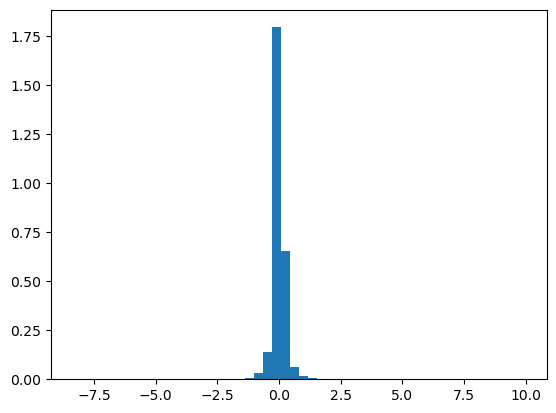

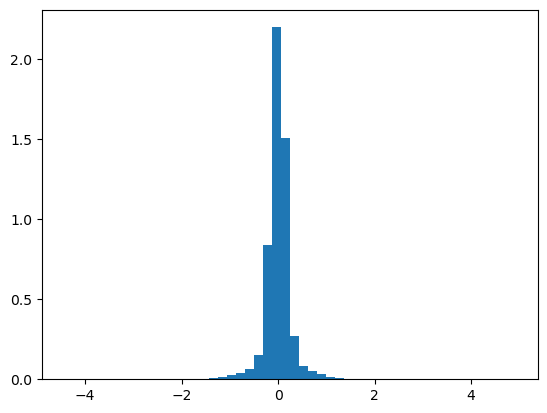

In [5]:
nc = 3
tar = gprior(dim)
tar.set_parameters(cov0)
pro = mix_normal(dim)
a = tar.sampler(10000)

pro.em_algorithm(a,nc,cov0,301)
weights = pro.weights
covs = pro.covs
gs = pro.gs
print(weights, covs, gs)

# covs = np.array([np.cov(a[:,0], a[:,1])])
b = pro.sampler(10000)
plt.hist(a[:,0], bins = 50, density = True)
plt.show()
plt.hist(b[:,0], bins = 50, density = True)
plt.show()

In [9]:
Itrnum = 2100
sample_size = 2000
target = 'gprior'
proposal = 'mix_normal'

MyIM = IndMH(Itrnum, dim, target, proposal)
MyIM.set_distribution_parameters(cov0, nc, weights, covs)
est = BF(sample_size, weights, cov0, gs, input, output)
estcmc = BF(sample_size, weights, cov0, gs, input, output)
tar = gprior(dim)
tar.set_parameters(cov0)

9.27777354877288e-59
9.27777354877288e-59


In [10]:
epoch = 20
cmc_mean = []
imhcv_mean = []
print("start")
for i in range(epoch):
    data = MyIM.IMH()
    print(data[2].mean())
    est.sample_loader(data[0],data[1],data[2])
    m,v= est.IMCV()
    imhcv_mean.append(m)
    # datacmc = tar.sampler(sample_size)
    # estcmc.cmc_loader(datacmc)
    # mc,vc = estcmc.CMC()
    mc,vc = est.IM()
    cmc_mean.append(mc)
    if (i + 1) % 1 == 0:
        print(i + 1, "replications completed !")

start
0.7159409743497769
[[ 1.39140573e-27 -1.18587304e-27]
 [-1.18587304e-27  2.30967638e-27]]
[[2.30967638e-27 1.33421183e-27]
 [1.33421183e-27 1.39140573e-27]]
[[ 1.         -0.66150897]
 [-0.66150897  1.        ]]
[[1.         0.74425597]
 [0.74425597 1.        ]]
1 replications completed !


KeyboardInterrupt: 

In [8]:
print(np.array(imhcv_mean).var())
print(np.array(cmc_mean).var())
print(np.array(imhcv_mean).mean())
print(np.array(cmc_mean).mean())
print(np.array(cmc_mean).var()/np.array(imhcv_mean).var())

4.2547469348473753e-38
8.635797344138919e-36
4.732167001326076e-20
6.741777593729682e-19
202.9685308287013
